# TDE 03 — Construção do Baseline e Avaliação de Modelos
## Previsão de Consumo de Energia Elétrica Residencial (kWh)

**Notebook individual de:** Ingrid  
**Ênfase teórica e prática deste notebook:** Pré-processamento, tratamento de dados e Engenharia de Recursos  
**Tipo de problema:** Regressão | **Baselines:** Regressão Linear e Árvore de Decisão (`DecisionTreeRegressor`) | **Métricas:** MAE, MSE, RMSE e R²

O projeto segue um **modelo acumulativo em escada**: cada notebook contém todas as etapas anteriores e aprofunda a etapa de seu responsável .

| Etapa | Responsável | Conteúdo | Incluída |
|---|---|---|---|
| 1 | Lia | Geração do dataset + Análise Exploratória de Dados (EDA) |  neste notebook |
| 2 | Ingrid | Pré-processamento, tratamento de dados e Engenharia de Recursos |  neste notebook |
| 3 | Clara | Divisão dos dados em Treino e Teste (train_test_split) | — |
| 4 | Daniel | Baseline 1: Regressão Linear | — |
| 5 | Michel | Métricas (MAE, MSE, RMSE, R²) e análise da Regressão Linear | — |
| 6 | Morya | Baseline 2: Árvore de Decisão para Regressão | — |
| 7 | Taliciane | Métricas da Árvore de Decisão e gráficos de erro | — |
| 8 | Wesley | Análise comparativa final, discussão crítica e conclusões | — |

**Requisitos:** Python 3.9+, `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`.

# Etapa 1 — Geração do Dataset e Análise Exploratória (EDA)
**Responsável: Lia**

## 1.1 Contexto do problema
Queremos **prever o consumo mensal de energia elétrica de uma residência (kWh)** a partir de características da casa, da família e do clima. Como o alvo (`consumo_kwh`) é um **valor contínuo**, trata-se de um problema de **regressão supervisionada**.

Geramos os dados por simulação, com regras inspiradas na realidade (mais moradores, maior área e mais ar-condicionado → mais consumo; energia solar reduz o consumo da rede) e **defeitos propositais** (valores ausentes, duplicatas, valores impossíveis e outliers). Isso torna as etapas seguintes (pré-processamento, divisão, modelagem) realistas.

> Como os dados vêm de uma simulação com `seed` fixa, **todos os resultados são reprodutíveis**.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
TARGET = "consumo_kwh"
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
print("Ambiente pronto.")

Ambiente pronto.


## 1.2 Geração do dataset
Variáveis simuladas:

| Variável | Descrição |
|---|---|
| `id_residencia` | identificador |
| `mes` | mês de referência (1–12) |
| `temperatura_media` | temperatura média do mês (°C), com sazonalidade |
| `num_moradores` | pessoas na residência |
| `tipo_residencia` | `casa` ou `apartamento` |
| `area_m2` | área construída |
| `renda_familiar` | renda mensal (R$) |
| `num_ar_condicionado` | aparelhos de ar-condicionado |
| `num_geladeiras` | geladeiras/freezers |
| `possui_energia_solar` | 1 se tem painel solar |
| `horas_home_office` | horas diárias de trabalho em casa |
| `idade_imovel_anos` | idade do imóvel (**variável sem efeito real** — serve para testar se os modelos a ignoram) |
| `consumo_kwh` | **alvo**: consumo mensal em kWh |

In [ ]:
def gerar_dataset(n=1500, seed=SEED):
    rng = np.random.default_rng(seed)

    mes = rng.integers(1, 13, n)
    temperatura = 27 + 3 * np.sin(2 * np.pi * (mes - 4) / 12) + rng.normal(0, 1.5, n)
    moradores = np.clip(rng.poisson(2.2, n) + 1, 1, 8)
    tipo = rng.choice(["casa", "apartamento"], n, p=[0.6, 0.4])
    area = np.where(tipo == "casa", rng.normal(110, 35, n), rng.normal(65, 20, n))
    area = np.clip(area, 25, 350).round(1)
    renda = (rng.lognormal(7.9, 0.5, n) * (0.7 + area / 150)).round(0)
    ar = np.clip(rng.poisson(0.4 + renda / 6000, n), 0, 5)
    geladeiras = rng.choice([1, 2], n, p=[0.85, 0.15])
    solar = rng.binomial(1, np.clip(renda / 40000, 0.02, 0.4))
    home_office = rng.integers(0, 9, n)
    idade = rng.integers(1, 41, n).astype(float)

    # regra "verdadeira" (desconhecida para o modelo) + ruído
    efeito_ar = ar * np.maximum(temperatura - 23, 0) * 14      # relação NÃO linear (interação ar x calor)
    consumo = (35 + 0.9 * area + 22 * moradores + 28 * geladeiras
               + 6 * home_office + 3 * (temperatura - 27) + efeito_ar)
    consumo = consumo * np.where(solar == 1, 0.72, 1.0)
    consumo = consumo + rng.normal(0, 18, n)
    consumo = np.clip(consumo, 25, None).round(1)

    df = pd.DataFrame({
        "id_residencia": np.arange(1, n + 1),
        "mes": mes,
        "temperatura_media": temperatura.round(1),
        "num_moradores": moradores,
        "tipo_residencia": tipo,
        "area_m2": area,
        "renda_familiar": renda,
        "num_ar_condicionado": ar,
        "num_geladeiras": geladeiras,
        "possui_energia_solar": solar,
        "horas_home_office": home_office,
        "idade_imovel_anos": idade,
        "consumo_kwh": consumo,
    })

    # ---- defeitos propositais (realismo) ----
    for col, frac in [("renda_familiar", 0.06), ("area_m2", 0.03), ("idade_imovel_anos", 0.04)]:
        idx = rng.choice(n, int(frac * n), replace=False)
        df.loc[idx, col] = np.nan                                  # valores ausentes
    df.loc[rng.choice(n, 3, replace=False), "area_m2"] = -1        # valores impossíveis (erro de digitação)
    df.loc[rng.choice(n, 8, replace=False), "consumo_kwh"] *= 2.8  # outliers extremos (erro de medição)
    duplicadas = df.sample(8, random_state=seed)                   # linhas duplicadas
    df = pd.concat([df, duplicadas], ignore_index=True)
    return df

df_raw = gerar_dataset()
df_raw.to_csv("dataset_consumo_energia.csv", index=False)
print("Dataset gerado e salvo em 'dataset_consumo_energia.csv'")
print("Formato:", df_raw.shape)
df_raw.head()

Dataset gerado e salvo em 'dataset_consumo_energia.csv'
Formato: (1508, 13)


,id_residencia,mes,temperatura_media,num_moradores,tipo_residencia,area_m2,renda_familiar,num_ar_condicionado,num_geladeiras,possui_energia_solar,horas_home_office,idade_imovel_anos,consumo_kwh
0,1,2,24.30,6,apartamento,27.40,635.00,0,1,0,2,20.00,197.20
1,2,10,28.70,3,casa,61.10,"1,603.00",0,1,0,1,33.00,190.10
2,3,8,26.20,3,casa,128.20,"5,291.00",0,1,0,5,6.00,273.90
3,4,6,27.40,3,casa,60.50,"2,474.00",0,1,0,0,22.00,182.50
4,5,6,28.20,1,casa,132.00,"3,223.00",0,1,0,0,34.00,218.20


## 1.3 Análise Exploratória de Dados (EDA)

**Teoria.** A EDA é o primeiro contato com os dados. Seus objetivos são: (i) entender a estrutura (tipos, tamanho); (ii) detectar problemas de qualidade (nulos, duplicatas, outliers, valores impossíveis); (iii) conhecer a distribuição do alvo; (iv) levantar hipóteses sobre quais variáveis explicam o alvo (correlações, comparações por grupo). **Nada é "corrigido" aqui** — apenas diagnosticado; a correção é a Etapa 2.

### 1.3.1 Estrutura e tipos

In [ ]:
print("Linhas x colunas:", df_raw.shape)
print()
df_raw.info()

Linhas x colunas: (1508, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_residencia         1508 non-null   int64  
 1   mes                   1508 non-null   int64  
 2   temperatura_media     1508 non-null   float64
 3   num_moradores         1508 non-null   int64  
 4   tipo_residencia       1508 non-null   object 
 5   area_m2               1464 non-null   float64
 6   renda_familiar        1418 non-null   float64
 7   num_ar_condicionado   1508 non-null   int64  
 8   num_geladeiras        1508 non-null   int64  
 9   possui_energia_solar  1508 non-null   int64  
 10  horas_home_office     1508 non-null   int64  
 11  idade_imovel_anos     1448 non-null   float64
 12  consumo_kwh           1508 non-null   float64
dtypes: float64(5), int64(7), object(1)
memory usage: 153.3+ KB


### 1.3.2 Estatísticas descritivas

In [ ]:
display(df_raw.describe().T)
print("\nVariável categórica:")
display(df_raw["tipo_residencia"].value_counts(normalize=True).rename("proporção").to_frame())

,count,mean,std,min,25%,50%,75%,max
id_residencia,"1,508.00",750.79,432.72,1.00,377.75,750.50,"1,124.25","1,500.00"
mes,"1,508.00",6.58,3.47,1.00,4.00,7.00,10.00,12.00
temperatura_media,"1,508.00",26.92,2.60,20.00,24.90,26.90,28.90,34.40
num_moradores,"1,508.00",3.16,1.48,1.00,2.00,3.00,4.00,8.00
area_m2,"1,464.00",90.50,37.36,-1.00,62.08,85.65,115.58,213.60
renda_familiar,"1,418.00","3,953.26","2,295.17",635.00,"2,410.00","3,344.50","4,841.50","21,711.00"
num_ar_condicionado,"1,508.00",1.08,1.08,0.00,0.00,1.00,2.00,5.00
num_geladeiras,"1,508.00",1.16,0.36,1.00,1.00,1.00,1.00,2.00
possui_energia_solar,"1,508.00",0.10,0.29,0.00,0.00,0.00,0.00,1.00
horas_home_office,"1,508.00",3.99,2.59,0.00,2.00,4.00,6.00,8.00



Variável categórica:


,proporção
tipo_residencia,
casa,0.59
apartamento,0.41


**O que observar:** compare `mean` com `50%` (mediana) — grande diferença indica assimetria; observe `min`/`max` (`area_m2` com mínimo negativo é impossível; o `max` de `consumo_kwh` está muito acima do `75%`).

### 1.3.3 Qualidade dos dados

,nulos,% nulos
area_m2,44,2.92
renda_familiar,90,5.97
idade_imovel_anos,60,3.98


Linhas duplicadas: 8
Áreas <= 0 (impossíveis): 3


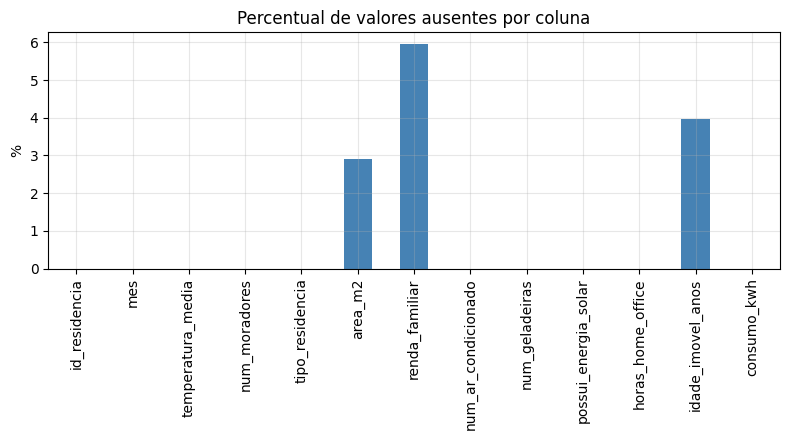

In [ ]:
qualidade = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
})
display(qualidade[qualidade["nulos"] > 0])
print("Linhas duplicadas:", df_raw.duplicated().sum())
print("Áreas <= 0 (impossíveis):", (df_raw["area_m2"] <= 0).sum())

fig, ax = plt.subplots()
qualidade["% nulos"].plot.bar(ax=ax, color="steelblue")
ax.set_title("Percentual de valores ausentes por coluna"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

### 1.3.4 Distribuição da variável-alvo
Entender o alvo é essencial em regressão: sua escala define o que é um "erro grande" e sua assimetria/outliers influenciam métricas como RMSE e R².

Média: 297.4 | Mediana: 278.6 | Desvio: 111.6 | Assimetria: 1.95


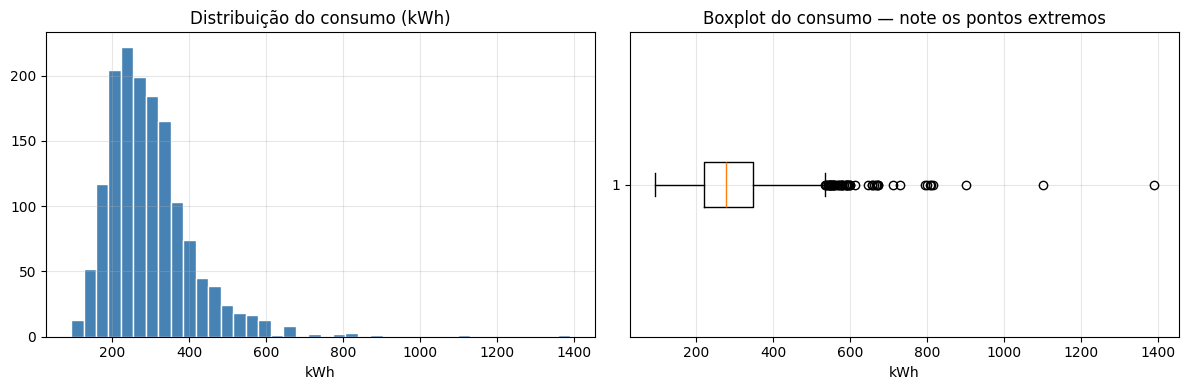

In [ ]:
y_raw = df_raw[TARGET]
print(f"Média: {y_raw.mean():.1f} | Mediana: {y_raw.median():.1f} | Desvio: {y_raw.std():.1f} | Assimetria: {y_raw.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_raw, bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribuição do consumo (kWh)"); axes[0].set_xlabel("kWh")
axes[1].boxplot(y_raw, vert=False)
axes[1].set_title("Boxplot do consumo — note os pontos extremos"); axes[1].set_xlabel("kWh")
plt.tight_layout(); plt.show()

### 1.3.5 Distribuição das variáveis numéricas

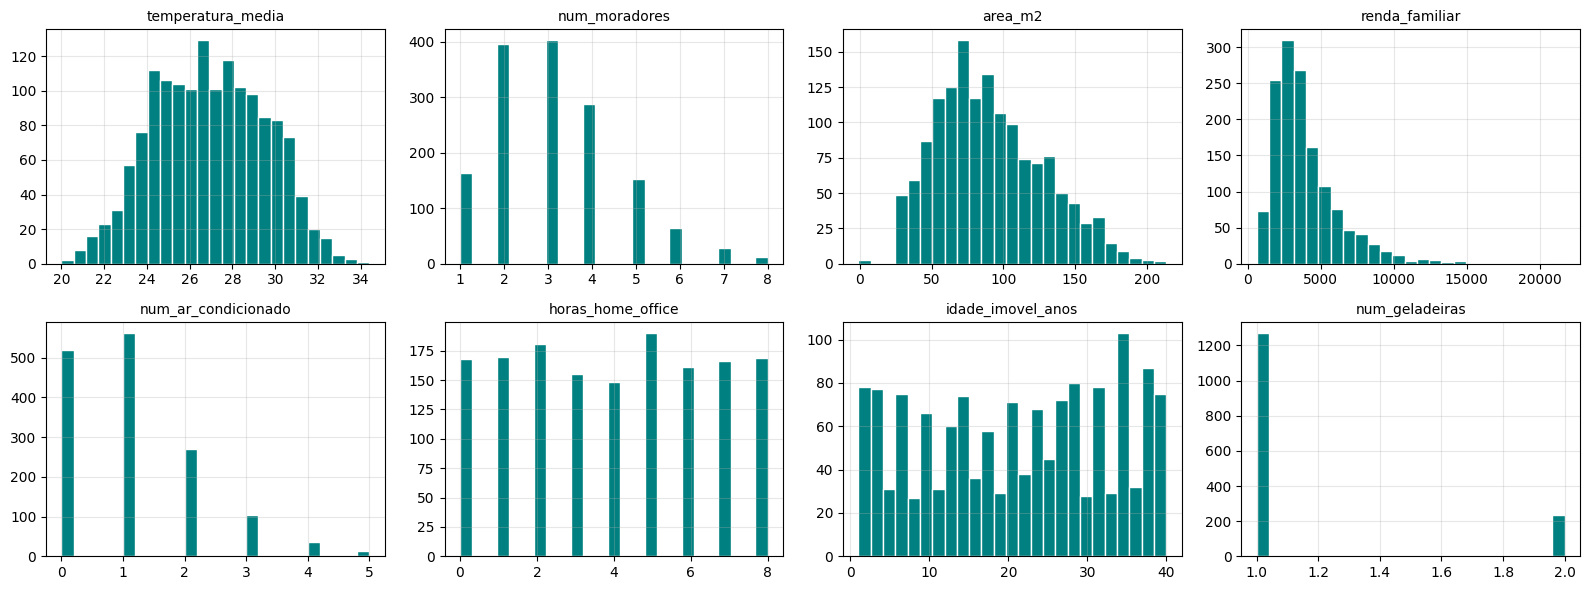

In [ ]:
num_cols_eda = ["temperatura_media", "num_moradores", "area_m2", "renda_familiar",
                "num_ar_condicionado", "horas_home_office", "idade_imovel_anos", "num_geladeiras"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), num_cols_eda):
    ax.hist(df_raw[col].dropna(), bins=25, color="teal", edgecolor="white")
    ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()

### 1.3.6 Relações com o alvo
**Correlação de Pearson** mede relação **linear** (−1 a 1). Ela não captura relações não lineares nem interações — por isso complementamos com gráficos e comparações por grupo.

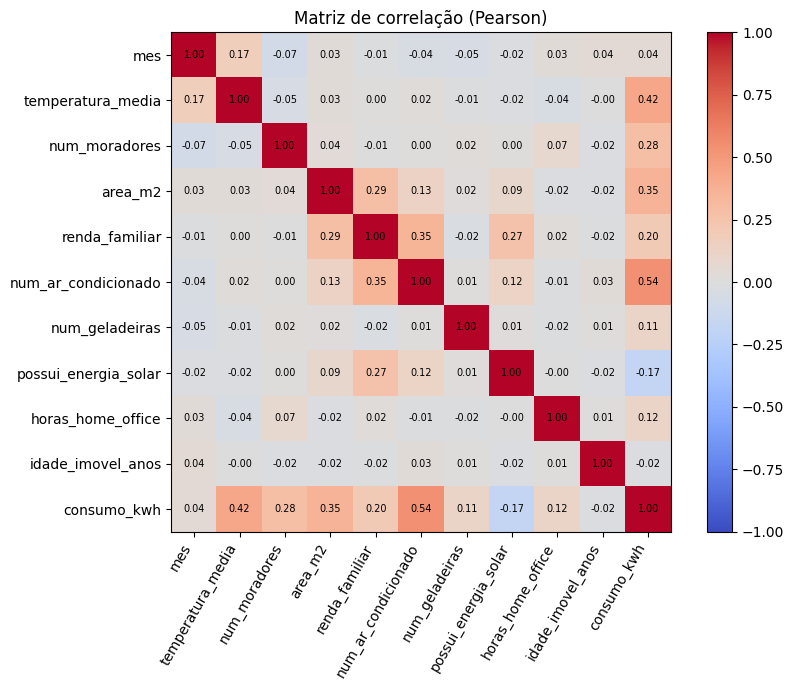

Correlação com o alvo:


,correlação
num_ar_condicionado,0.54
temperatura_media,0.42
area_m2,0.35
num_moradores,0.28
renda_familiar,0.20
horas_home_office,0.12
num_geladeiras,0.11
mes,0.04
idade_imovel_anos,-0.02
possui_energia_solar,-0.17


In [ ]:
num_df = df_raw.select_dtypes(include="number").drop(columns=["id_residencia"])
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); plt.colorbar(im); ax.set_title("Matriz de correlação (Pearson)")
plt.tight_layout(); plt.show()

print("Correlação com o alvo:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("correlação"))

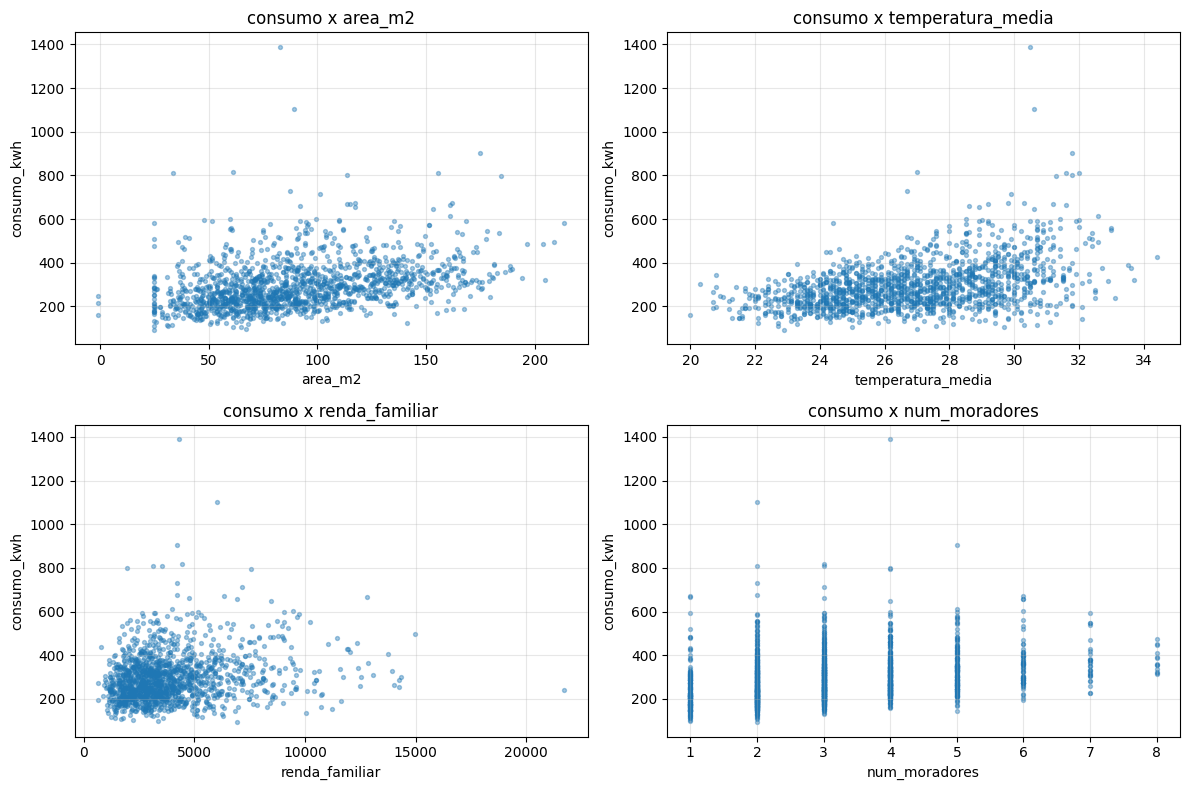

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["area_m2", "temperatura_media", "renda_familiar", "num_moradores"]):
    ax.scatter(df_raw[col], df_raw[TARGET], s=8, alpha=0.4)
    ax.set_xlabel(col); ax.set_ylabel("consumo_kwh"); ax.set_title(f"consumo x {col}")
plt.tight_layout(); plt.show()

### 1.3.7 Comparação por grupos

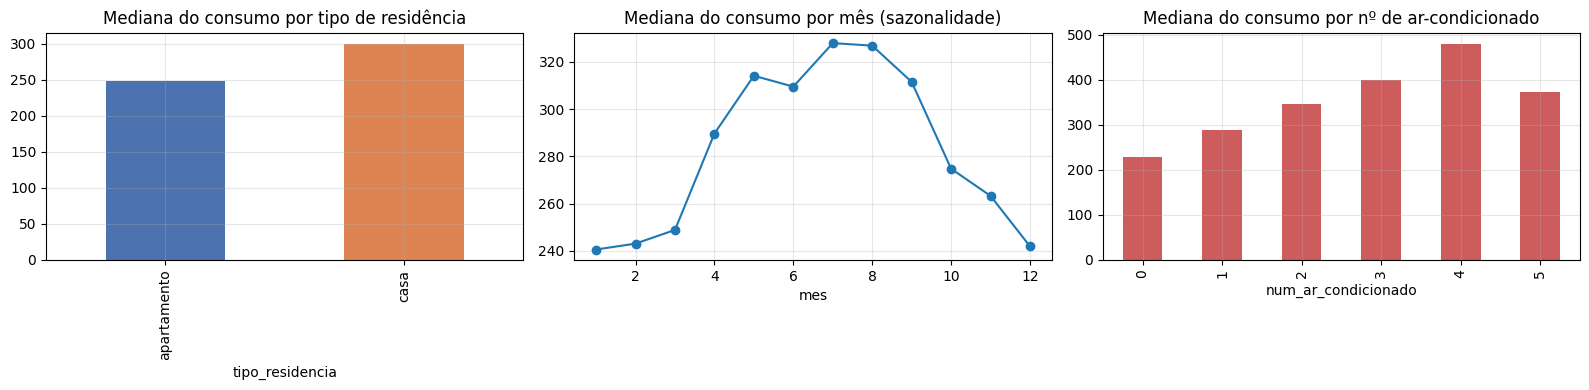

,count,mean,std,min,25%,50%,75%,max
possui_energia_solar,,,,,,,,
0,"1,363.00",303.68,110.64,111.20,227.10,285.20,350.80,"1,390.20"
1,145.00,238.47,103.91,92.80,171.20,219.90,269.20,903.00


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_raw.groupby("tipo_residencia")[TARGET].median().plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Mediana do consumo por tipo de residência")

df_raw.groupby("mes")[TARGET].median().plot(ax=axes[1], marker="o")
axes[1].set_title("Mediana do consumo por mês (sazonalidade)")

df_raw.groupby("num_ar_condicionado")[TARGET].median().plot.bar(ax=axes[2], color="indianred")
axes[2].set_title("Mediana do consumo por nº de ar-condicionado")
plt.tight_layout(); plt.show()

display(df_raw.groupby("possui_energia_solar")[TARGET].describe())

### 1.3.8 Conclusões da EDA (insumos para as próximas etapas)
1. **Valores ausentes** em `renda_familiar`, `area_m2` e `idade_imovel_anos` → exigem imputação (Etapa 2).
2. **Duplicatas** e **áreas negativas** → erros de coleta; devem ser removidos/corrigidos.
3. **Outliers extremos** em `consumo_kwh` (muito acima do restante) → provável erro de medição; decidir tratamento.
4. `area_m2`, `num_moradores` e `num_ar_condicionado` têm relação positiva clara com o consumo; `temperatura_media` e `mes` indicam **sazonalidade**.
5. `renda_familiar` é assimétrica à direita → candidata a transformação logarítmica.
6. A relação entre ar-condicionado e temperatura sugere **não linearidade/interação** — algo que a Regressão Linear simples pode não capturar e a Árvore de Decisão pode.

# Etapa 2 — Pré-processamento, Tratamento de Dados e Engenharia de Recursos
**Responsável: Ingrid**

## 2.1 Teoria
Modelos não aprendem com "dados crus": precisam de dados **limpos, numéricos e informativos**. Esta etapa tem três frentes:

1. **Limpeza determinística** (regras que não dependem de estatísticas dos dados): remover duplicatas, tratar valores impossíveis.
2. **Engenharia de recursos (*feature engineering*)**: criar variáveis novas a partir das existentes, usando conhecimento do domínio.
3. **Transformações estatísticas** (imputação, padronização, codificação de categorias): são **aprendidas** a partir dos dados e, por isso, devem ser ajustadas **apenas no treino** para evitar **vazamento de dados (*data leakage*)**. Por isso as definimos agora como um `ColumnTransformer`, mas só o **ajustamos (`fit`) depois da divisão treino/teste** — dentro de um `Pipeline`.

In [ ]:
df = df_raw.copy()

# 1) duplicatas
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# 2) valores impossíveis -> viram NaN (serão imputados no pipeline)
n_area_neg = (df["area_m2"] <= 0).sum()
df.loc[df["area_m2"] <= 0, "area_m2"] = np.nan

# 3) outliers extremos do alvo (regra IQR com fator 3 = "outlier extremo")
q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 3 * iqr
n_out = (df[TARGET] > limite_sup).sum()
df_clean = df[df[TARGET] <= limite_sup].reset_index(drop=True)

print(f"Duplicatas removidas: {n_dup}")
print(f"Áreas impossíveis convertidas em NaN: {n_area_neg}")
print(f"Outliers extremos do alvo removidos (> {limite_sup:.0f} kWh): {n_out}")
print(f"Formato: {df_raw.shape} -> {df_clean.shape}")

Duplicatas removidas: 8
Áreas impossíveis convertidas em NaN: 3
Outliers extremos do alvo removidos (> 725 kWh): 9
Formato: (1508, 13) -> (1491, 13)


In [ ]:
def criar_features(d):
    d = d.copy()
    d["area_por_morador"] = d["area_m2"] / d["num_moradores"]
    d["total_eletro"] = d["num_ar_condicionado"] + d["num_geladeiras"]
    d["renda_log"] = np.log1p(d["renda_familiar"])
    d["mes_sin"] = np.sin(2 * np.pi * d["mes"] / 12)
    d["mes_cos"] = np.cos(2 * np.pi * d["mes"] / 12)
    d["periodo_chuvoso"] = d["mes"].between(2, 5).astype(int)
    return d

df_fe = criar_features(df_clean)

num_features = ["temperatura_media", "num_moradores", "area_m2", "num_ar_condicionado",
                "num_geladeiras", "horas_home_office", "idade_imovel_anos",
                "area_por_morador", "total_eletro", "renda_log", "mes_sin", "mes_cos"]
cat_features = ["tipo_residencia"]
bin_features = ["possui_energia_solar", "periodo_chuvoso"]
FEATURES = num_features + cat_features + bin_features

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features),
    ("bin", "passthrough", bin_features),
])

print(f"{len(FEATURES)} variáveis de entrada definidas.")
print("Pré-processador definido (ainda NÃO ajustado — o fit será feito só no treino).")
df_fe.head()

15 variáveis de entrada definidas.
Pré-processador definido (ainda NÃO ajustado — o fit será feito só no treino).


,id_residencia,mes,temperatura_media,num_moradores,tipo_residencia,area_m2,renda_familiar,num_ar_condicionado,num_geladeiras,possui_energia_solar,horas_home_office,idade_imovel_anos,consumo_kwh,area_por_morador,total_eletro,renda_log,mes_sin,mes_cos,periodo_chuvoso
0,1,2,24.30,6,apartamento,27.40,635.00,0,1,0,2,20.00,197.20,4.57,1,6.46,0.87,0.50,1
1,2,10,28.70,3,casa,61.10,"1,603.00",0,1,0,1,33.00,190.10,20.37,1,7.38,-0.87,0.50,0
2,3,8,26.20,3,casa,128.20,"5,291.00",0,1,0,5,6.00,273.90,42.73,1,8.57,-0.87,-0.50,0
3,4,6,27.40,3,casa,60.50,"2,474.00",0,1,0,0,22.00,182.50,20.17,1,7.81,0.00,-1.00,0
4,5,6,28.20,1,casa,132.00,"3,223.00",0,1,0,0,34.00,218.20,132.00,1,8.08,0.00,-1.00,0


---
### APROFUNDAMENTO DA ETAPA 2 —
*Pré-processamento, tratamento de dados e Engenharia de Recursos*
---

## 2.2 Aprofundamento — decisões de tratamento (com evidências)

### 2.2.1 Valores ausentes: quais estratégias existem?
| Estratégia | Quando usar | Risco |
|---|---|---|
| Remover linhas | poucos nulos, aleatórios | perde dados e pode enviesar |
| Média | variável simétrica | sensível a outliers; reduz variância |
| **Mediana** | variável assimétrica/com outliers | também reduz variância |
| Moda | categóricas | pode inflar a categoria dominante |
| KNN/modelo | relações fortes entre variáveis | mais custo/complexidade |

Escolhemos **mediana** (numéricas) e **moda** (categóricas): simples, robustas e adequadas a baselines. Veja o efeito em `renda_familiar` (apenas ilustração, em uma cópia):

In [ ]:
renda = df_clean[["renda_familiar"]]
comp = pd.DataFrame({
    "original (sem nulos)": renda["renda_familiar"].dropna().describe(),
    "imputada por média": pd.Series(SimpleImputer(strategy="mean").fit_transform(renda).ravel()).describe(),
    "imputada por mediana": pd.Series(SimpleImputer(strategy="median").fit_transform(renda).ravel()).describe(),
}).loc[["count", "mean", "std", "50%"]]
display(comp)
print("Nulos tratados:", df_clean["renda_familiar"].isna().sum(), "-> o desvio-padrão diminui um pouco após imputar (efeito esperado).")

,original (sem nulos),imputada por média,imputada por mediana
count,"1,401.00","1,491.00","1,491.00"
mean,"3,952.18","3,952.18","3,915.29"
std,"2,295.53","2,225.12","2,229.88"
50%,"3,341.00","3,434.00","3,341.00"


Nulos tratados: 90 -> o desvio-padrão diminui um pouco após imputar (efeito esperado).


### 2.2.2 Outliers: remover, limitar ou manter?
Removemos apenas os **extremos** (acima de Q3 + 3·IQR), pois são consistentes com erro de medição. Outliers "moderados" (entre 1,5·IQR e 3·IQR) foram **mantidos**: podem ser consumos legítimos de casas grandes. Veja o antes/depois:

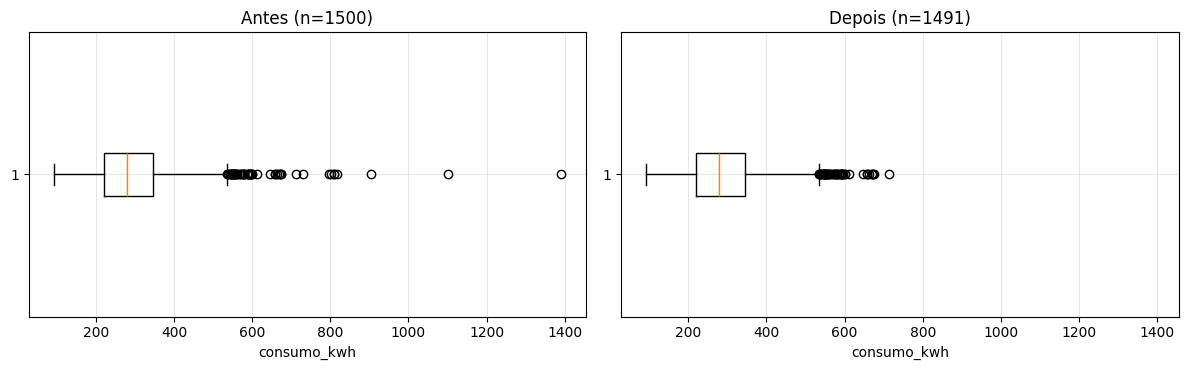

Outliers moderados mantidos: 46


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
axes[0].boxplot(df[TARGET], vert=False); axes[0].set_title(f"Antes (n={len(df)})")
axes[1].boxplot(df_clean[TARGET], vert=False); axes[1].set_title(f"Depois (n={len(df_clean)})")
for ax in axes: ax.set_xlabel("consumo_kwh")
plt.tight_layout(); plt.show()

moderados = ((df_clean[TARGET] > q3 + 1.5 * iqr)).sum()
print(f"Outliers moderados mantidos: {moderados}")

### 2.2.3 Engenharia de recursos — o que criamos e por quê
| Nova variável | Justificativa |
|---|---|
| `area_por_morador` | densidade de ocupação: casas grandes com poucos moradores se comportam diferente |
| `total_eletro` | resume a carga de equipamentos de refrigeração |
| `renda_log` | `renda` é assimétrica; o `log` aproxima de uma distribuição simétrica |
| `mes_sin`, `mes_cos` | **codificação cíclica**: dezembro (12) e janeiro (1) são vizinhos, mas numericamente distantes; seno/cosseno preservam essa circularidade |
| `periodo_chuvoso` | indicador sazonal (fev–mai) |
| `tipo_residencia` → one-hot | modelos numéricos não aceitam texto; `drop="first"` evita colinearidade perfeita (*dummy trap*) |

Veja o efeito da transformação logarítmica e as novas correlações:

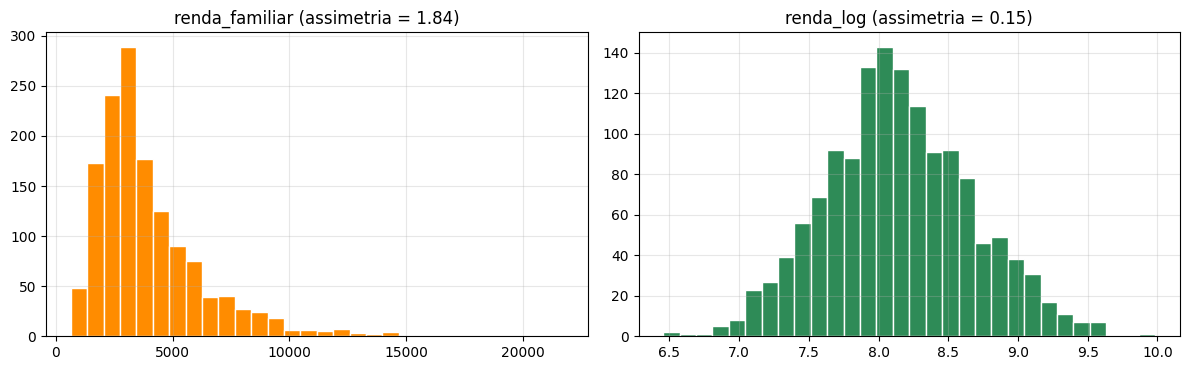

,correlação com o alvo
total_eletro,0.59
mes_cos,-0.30
renda_log,0.23
mes_sin,-0.18
periodo_chuvoso,-0.08
area_por_morador,-0.00


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(df_fe["renda_familiar"].dropna(), bins=30, color="darkorange", edgecolor="white")
axes[0].set_title(f"renda_familiar (assimetria = {df_fe['renda_familiar'].skew():.2f})")
axes[1].hist(df_fe["renda_log"].dropna(), bins=30, color="seagreen", edgecolor="white")
axes[1].set_title(f"renda_log (assimetria = {df_fe['renda_log'].skew():.2f})")
plt.tight_layout(); plt.show()

novas = ["area_por_morador", "total_eletro", "renda_log", "mes_sin", "mes_cos", "periodo_chuvoso"]
display(df_fe[novas + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlação com o alvo"))

### 2.2.4 Padronização (`StandardScaler`) e por que o `fit` só no treino
`z = (x − média) / desvio`. Para a **Regressão Linear**, padronizar não muda as previsões, mas torna os **coeficientes comparáveis**. Para **Árvores**, é desnecessário (mas inofensivo) — usamos o mesmo pré-processador nos dois modelos para uma comparação justa.

**Vazamento de dados:** se calculássemos médias/medianas/desvios usando *todo* o dataset, o teste "vazaria" informação para o treino e as métricas ficariam otimistas. O `Pipeline` garante que `fit` ocorra só no treino e o teste apenas receba `transform`.

### 2.2.5 Checagem final do dataset tratado

In [ ]:
resumo = pd.DataFrame({
    "tipo": df_fe[FEATURES].dtypes.astype(str),
    "nulos restantes": df_fe[FEATURES].isna().sum(),
})
display(resumo)
print("Nulos ainda existem de propósito: serão imputados DENTRO do pipeline, após a divisão treino/teste.")
print("Nulos no alvo:", df_fe[TARGET].isna().sum())

,tipo,nulos restantes
temperatura_media,float64,0
num_moradores,int64,0
area_m2,float64,47
num_ar_condicionado,int64,0
num_geladeiras,int64,0
horas_home_office,int64,0
idade_imovel_anos,float64,60
area_por_morador,float64,47
total_eletro,int64,0
renda_log,float64,90


Nulos ainda existem de propósito: serão imputados DENTRO do pipeline, após a divisão treino/teste.
Nulos no alvo: 0
